# CC sensitivity to calibrated parameters (one at a time)

Scales each calibrated METANET parameter (`eta_high`, `K`, `tau`, `p_crit`, `v_free`, `a`) on its own by
−1% … +1% in every segment, holds the nominal-optimal VSL policy fixed, and re-simulates. Everything else stays at
its calibrated value. CC is recomputed for each point from that model's own uncontrolled TTS, controlled TTS and
free-flow TTS, and is **not** clipped, so negative values (the policy made delay worse) show up.

At 0% every curve passes through the nominal CC. Set `SHOW_MAPE = True` to also draw the simulation MAPE of each
perturbed model on a right-hand axis.

In [6]:
%load_ext autoreload
%autoreload 2

import numpy as np

import sys, os
# Walk up to the repo root, so this works no matter where Jupyter was launched.
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
sys.path.insert(0, os.path.join(_root, "src"))

from paths import fig
from cc_analysis import one_at_a_time_cc, plot_param_sensitivity

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [11]:
DATE = "11_28"

# Perturbations as fractions: -1% to +1% in 0.05% steps (41 points, includes exactly 0).
PERTURB_PCT = np.arange(-20, 21) * 0.0005

# Also plot the sim MAPE of each perturbed model next to CC (right-hand axis).
SHOW_MAPE = True

suffix = "_with_mape" if SHOW_MAPE else ""
SAVE_PATH = fig(f"i24_cc_param_sensitivity_{DATE}{suffix}.pdf")

## Run the scan

Each parameter takes one pair of simulations (uncontrolled + controlled) per perturbation, so this is 6 × 41 runs.

In [12]:
pct, results, nominal_cc, mape_results, nominal_mape = one_at_a_time_cc(
    DATE, perturb_pct=PERTURB_PCT, return_mape=True
)

# Sanity check: at 0% every parameter must reproduce the nominal CC and MAPE.
i0 = int(np.argmin(np.abs(pct)))
assert pct[i0] == 0.0
assert all(abs(r[i0] - nominal_cc) < 1e-9 for r in results.values())
assert all(abs(m[i0] - nominal_mape) < 1e-9 for m in mape_results.values())
print(f"{DATE}: nominal CC = {nominal_cc:.1f}%, nominal sim MAPE = {nominal_mape:.1f}%")

11_28: nominal CC = 35.4%, nominal sim MAPE = 34.5%


## Plot

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved plot to /Users/shreyaar/Desktop/PhD/research/MPC/figs/i24_cc_param_sensitivity_11_28_with_mape.pdf


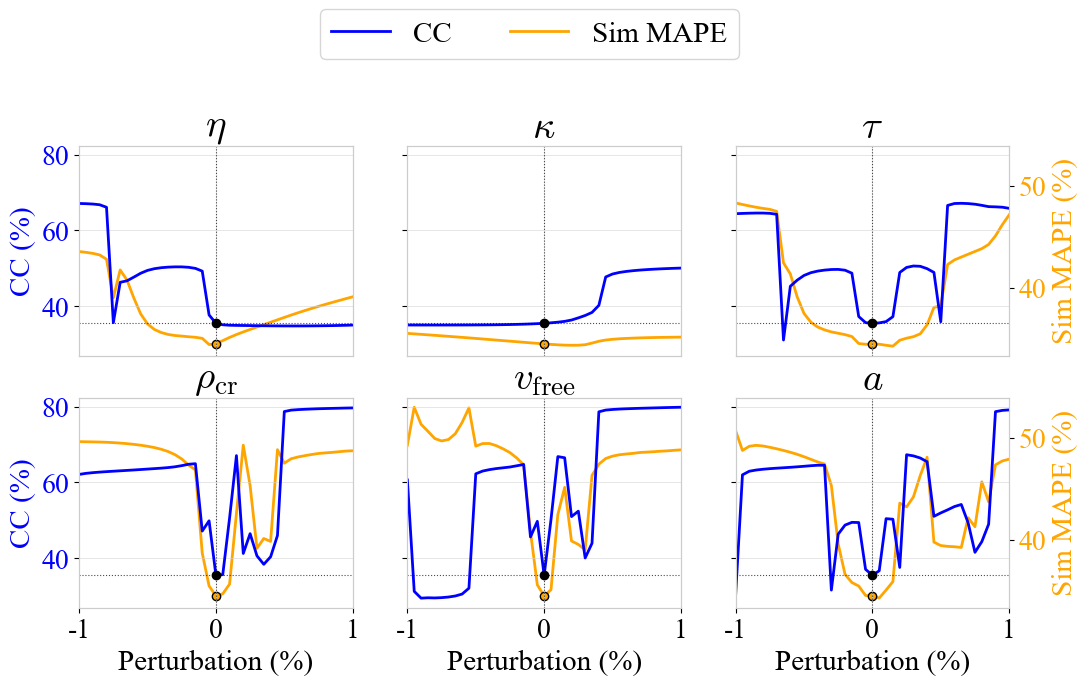

In [13]:
plot_param_sensitivity(
    pct, results, nominal_cc, save_path=SAVE_PATH,
    mape_results=mape_results if SHOW_MAPE else None,
    nominal_mape=nominal_mape,
);